# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

El entrenamiento se realiza en Colab para aprovechar la GPU:
**Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.

Requisitos previos (en tu fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:
- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.
- Entregar esta notebook ejecutada, con sus salidas.

**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Alumno 1 : Nicolas Duclos
- Alumno 2 : Damian Grimaldi

## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.

In [14]:
# TO-DO: completar con la URL de tu fork.
# Repo privado: https://<TOKEN>@github.com/<usuario>/tuia-dog-recognition-app.git
#REPO_URL = "https://github.com/DuclosNicolas/tuia-dog-recognition-app.git"

#!git clone $REPO_URL proyecto
#%cd proyecto

## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [15]:
#!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

In [2]:
import os
import sys
import json
import time
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

os.environ["USE_PGVECTOR"] = "false"

from lib.config import settings
from lib.bootstrap import build_classifier, build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k, precision_recall_f1, specificity
from lib.preprocessing import bgr_to_rgb, get_eval_transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = settings.data_path if settings.data_path.is_absolute() else ROOT / settings.data_path
DATASET_DIR = (
    settings.dataset_path
    if settings.dataset_path.is_absolute()
    else ROOT / settings.dataset_path
)
OUTPUT_DIR = (
    settings.output_path
    if settings.output_path.is_absolute()
    else ROOT / settings.output_path
)
MODEL_DIR = (
    settings.model_path
    if settings.model_path.is_absolute()
    else ROOT / settings.model_path
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(f"ROOT        : {ROOT}")
print(f"DATASET_DIR : {DATASET_DIR}")
print(f"EMBEDDING_DIM: {settings.embedding_dim}")
print(f"GPU CUDA    : {torch.cuda.is_available()}")

c:\Users\nicod\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT        : c:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app
DATASET_DIR : c:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\dataset
EMBEDDING_DIM: 512
GPU CUDA    : False


## 4. Dataset y splits

Descargar el dataset y cargar los splits y el conjunto independiente definidos en
`1-pre-processing.ipynb`.

In [4]:
df_splits = pd.read_csv(DATA_DIR / "splits.csv")
classes_meta = json.loads((DATA_DIR / "classes.json").read_text(encoding="utf-8"))
CLASS_NAMES: list[str] = classes_meta["classes"]
BREED_TO_IDX: dict[str, int] = classes_meta["breed_to_idx"]

df_ind = pd.read_csv(DATA_DIR / "independent_metadata.csv")
df_ind_single = df_ind[df_ind["scenario"] == "single_dog"].copy()
df_ind_single["label_idx"] = df_ind_single["breed"].map(BREED_TO_IDX)

print("Particiones cargadas desde splits.csv:")
print(df_splits["split"].value_counts().to_dict())
print(f"Total clases: {len(CLASS_NAMES)}")
print(f"\nConjunto independiente cargado ({len(df_ind)} imágenes totales):")
print(df_ind["scenario"].value_counts().to_dict())
print(f"  -> single_dog: {len(df_ind_single)} imágenes en {df_ind_single['breed'].nunique()} razas")

Particiones cargadas desde splits.csv:
{'train': 7730, 'test': 696, 'valid': 687}
Total clases: 70

Conjunto independiente cargado (163 imágenes totales):
{'single_dog': 118, 'no_dog': 30, 'multi_dog': 15}
  -> single_dog: 118 imágenes en 60 razas


## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

- Galería: imágenes de `train`. Consultas: `test` y el conjunto independiente.
- Para cada consulta, recupera las Top-10 y calcula NDCG@10 con relevancia binaria (misma raza).
- Reporta NDCG@10 medio, precision@10 y accuracy de la raza predicha, por separado para `test` y
  para el conjunto independiente.
- Compara `cosine` vs `l2`, analiza `TOP_K` y calibra `SIMILARITY_THRESHOLD` con validación.


In [5]:
from lib.schemas import Neighbor

similarity = build_similarity(settings, build_store(settings))


def compute_embeddings_matrix(df_subset: pd.DataFrame, extractor_fn) -> np.ndarray:
    embs = []
    for rel_path in df_subset["rel_path"]:
        img = cv2.imread(str(DATA_DIR / rel_path))
        embs.append(extractor_fn(img))
    return np.asarray(embs, dtype=np.float32)


def evaluate_retrieval(
    gal_embs: np.ndarray,
    gal_breeds: np.ndarray,
    qry_embs: np.ndarray,
    qry_breeds: np.ndarray,
    metric: str = "cosine",
    top_k: int = 10,
    threshold: float = 0.0,
) -> dict[str, float]:
    # Conteo de relevantes por raza en la galería para IDCG@k exacto
    breed_gallery_counts = pd.Series(gal_breeds).value_counts().to_dict()

    if metric == "cosine":
        # Como los vectores estan normalizados L2, el producto matricial es similitud coseno
        sim_matrix = qry_embs @ gal_embs.T
    elif metric == "l2":
        # Distancia euclidea exacta y transformacion 1 / (1 + d)
        dists = np.sqrt(
            np.maximum(
                0.0,
                np.sum(qry_embs**2, axis=1, keepdims=True)
                + np.sum(gal_embs**2, axis=1, keepdims=True).T
                - 2.0 * (qry_embs @ gal_embs.T),
            )
        )
        sim_matrix = 1.0 / (1.0 + dists)
    else:
        raise ValueError(f"Métrica desconocida: {metric}")

    ndcg_scores = []
    prec_scores = []
    correct_preds = 0
    prev_thresh = similarity.similarity_threshold
    similarity.similarity_threshold = threshold

    try:
        for i in range(len(qry_breeds)):
            sims = sim_matrix[i]
            top_idx = np.argpartition(-sims, kth=min(top_k, len(sims) - 1))[:top_k]
            top_idx = top_idx[np.argsort(-sims[top_idx])]

            neigh_breeds = gal_breeds[top_idx]
            neigh_scores = sims[top_idx]

            relevances = [1.0 if b == qry_breeds[i] else 0.0 for b in neigh_breeds]
            n_rel = breed_gallery_counts.get(qry_breeds[i], 0)
            ndcg_scores.append(ndcg_at_k(relevances, k=top_k, n_relevant=n_rel))
            prec_scores.append(float(np.mean(relevances)))

            neighbors_obj = [
                Neighbor(path="", breed=str(b), score=float(s))
                for b, s in zip(neigh_breeds, neigh_scores)
            ]
            pred_breed, _ = similarity.predict_breed_from_neighbors(neighbors_obj)
            if pred_breed == qry_breeds[i]:
                correct_preds += 1
    finally:
        similarity.similarity_threshold = prev_thresh

    return {
        "NDCG@10": round(float(np.mean(ndcg_scores)), 4),
        "Precision@10": round(float(np.mean(prec_scores)), 4),
        "Accuracy_raza": round(correct_preds / max(len(qry_breeds), 1), 4),
    }


df_train = df_splits[df_splits["split"] == "train"].reset_index(drop=True)
df_valid = df_splits[df_splits["split"] == "valid"].reset_index(drop=True)
df_test = df_splits[df_splits["split"] == "test"].reset_index(drop=True)

print("Extrayendo embeddings baseline (ResNet18 ImageNet)...")
emb_train_base = compute_embeddings_matrix(df_train, similarity.extract_embedding)
emb_valid_base = compute_embeddings_matrix(df_valid, similarity.extract_embedding)
emb_test_base = compute_embeddings_matrix(df_test, similarity.extract_embedding)
emb_ind_base = compute_embeddings_matrix(df_ind_single, similarity.extract_embedding)

gal_breeds = df_train["breed"].to_numpy()
valid_breeds = df_valid["breed"].to_numpy()
test_breeds = df_test["breed"].to_numpy()
ind_breeds = df_ind_single["breed"].to_numpy()

baseline_rows = []
for ds_name, q_embs, q_breeds in [
    ("test (700 imgs)", emb_test_base, test_breeds),
    ("independent (single_dog)", emb_ind_base, ind_breeds),
]:
    for metric in ["cosine", "l2"]:
        res = evaluate_retrieval(
            emb_train_base, gal_breeds, q_embs, q_breeds, metric=metric, top_k=10, threshold=0.0
        )
        baseline_rows.append({"Conjunto": ds_name, "Métrica": metric, **res})

df_baseline_eval = pd.DataFrame(baseline_rows)
display(df_baseline_eval)

INFO:lib.bootstrap:Using JSON file vector store
INFO:lib.services.similarity_service:Loading baseline feature extractor (ResNet18 ImageNet) on cpu


Extrayendo embeddings baseline (ResNet18 ImageNet)...


,Conjunto,Métrica,NDCG@10,Precision@10,Accuracy_raza
0,test (700 imgs),cosine,0.8739,0.8603,0.9325
1,test (700 imgs),l2,0.8739,0.8603,0.9325
2,independent (single_dog),cosine,0.6287,0.6186,0.7288
3,independent (single_dog),l2,0.6287,0.6186,0.7288


,TOP_K,NDCG@10,Precision@10,Accuracy_raza
0,1,0.9296,0.9296,0.9296
1,3,0.9060,0.8989,0.9339
2,5,0.8951,0.8859,0.9397
3,10,0.8739,0.8603,0.9325
4,15,0.8571,0.8398,0.9339
5,20,0.8456,0.8269,0.9325


,Threshold,Cobertura (no-unknown),Accuracy global (valid),Precisión sobre aceptadas
0,0.30,1.0000,0.9360,0.9360
1,0.35,1.0000,0.9360,0.9360
2,0.40,1.0000,0.9360,0.9360
3,0.45,1.0000,0.9360,0.9360
4,0.50,1.0000,0.9360,0.9360
5,0.55,1.0000,0.9360,0.9360
6,0.60,1.0000,0.9360,0.9360
7,0.65,1.0000,0.9360,0.9360
8,0.70,1.0000,0.9360,0.9360
9,0.75,1.0000,0.9360,0.9360


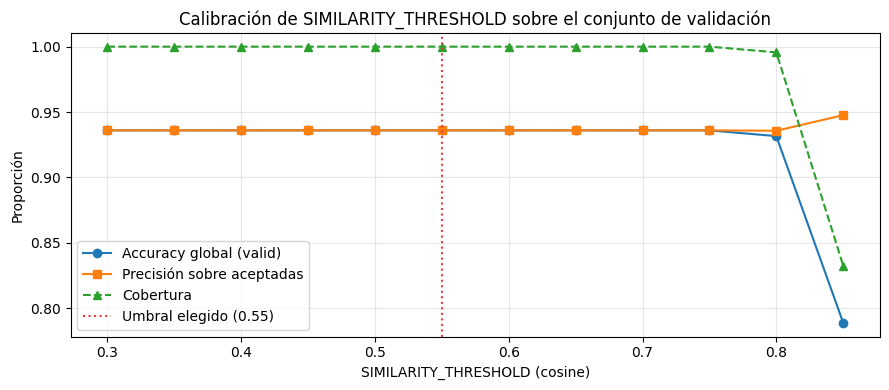

In [19]:
# 1. Efecto de TOP_K en test (cosine)
topk_rows = []
for k_val in [1, 3, 5, 10, 15, 20]:
    r = evaluate_retrieval(
        emb_train_base, gal_breeds, emb_test_base, test_breeds, metric="cosine", top_k=k_val, threshold=0.0
    )
    topk_rows.append({"TOP_K": k_val, **r})
display(pd.DataFrame(topk_rows))

# 2. Calibración de SIMILARITY_THRESHOLD sobre VALID (nunca sobre test)
sim_valid = emb_valid_base @ emb_train_base.T
thresholds = np.round(np.arange(0.30, 0.86, 0.05), 2)
cal_rows = []

for th in thresholds:
    prev_th = similarity.similarity_threshold
    similarity.similarity_threshold = float(th)
    known_count = 0
    correct_overall = 0
    correct_among_known = 0

    for i in range(len(valid_breeds)):
        sims = sim_valid[i]
        top_idx = np.argpartition(-sims, kth=10)[:10]
        top_idx = top_idx[np.argsort(-sims[top_idx])]
        neighs = [
            Neighbor(path="", breed=str(gal_breeds[j]), score=float(sims[j])) for j in top_idx
        ]
        pred, _ = similarity.predict_breed_from_neighbors(neighs)
        if pred != "unknown":
            known_count += 1
            if pred == valid_breeds[i]:
                correct_overall += 1
                correct_among_known += 1

    similarity.similarity_threshold = prev_th
    coverage = known_count / len(valid_breeds)
    acc_total = correct_overall / len(valid_breeds)
    acc_known = correct_among_known / max(known_count, 1)
    cal_rows.append(
        {
            "Threshold": th,
            "Cobertura (no-unknown)": round(coverage, 4),
            "Accuracy global (valid)": round(acc_total, 4),
            "Precisión sobre aceptadas": round(acc_known, 4),
        }
    )

df_cal = pd.DataFrame(cal_rows)
display(df_cal)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df_cal["Threshold"], df_cal["Accuracy global (valid)"], marker="o", label="Accuracy global (valid)")
ax.plot(df_cal["Threshold"], df_cal["Precisión sobre aceptadas"], marker="s", label="Precisión sobre aceptadas")
ax.plot(df_cal["Threshold"], df_cal["Cobertura (no-unknown)"], marker="^", linestyle="--", label="Cobertura")
ax.axvline(0.55, color="#e53e3e", linestyle=":", linewidth=1.5, label="Umbral elegido (0.55)")
ax.set_xlabel("SIMILARITY_THRESHOLD (cosine)")
ax.set_ylabel("Proporción")
ax.set_title("Calibración de SIMILARITY_THRESHOLD sobre el conjunto de validación")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

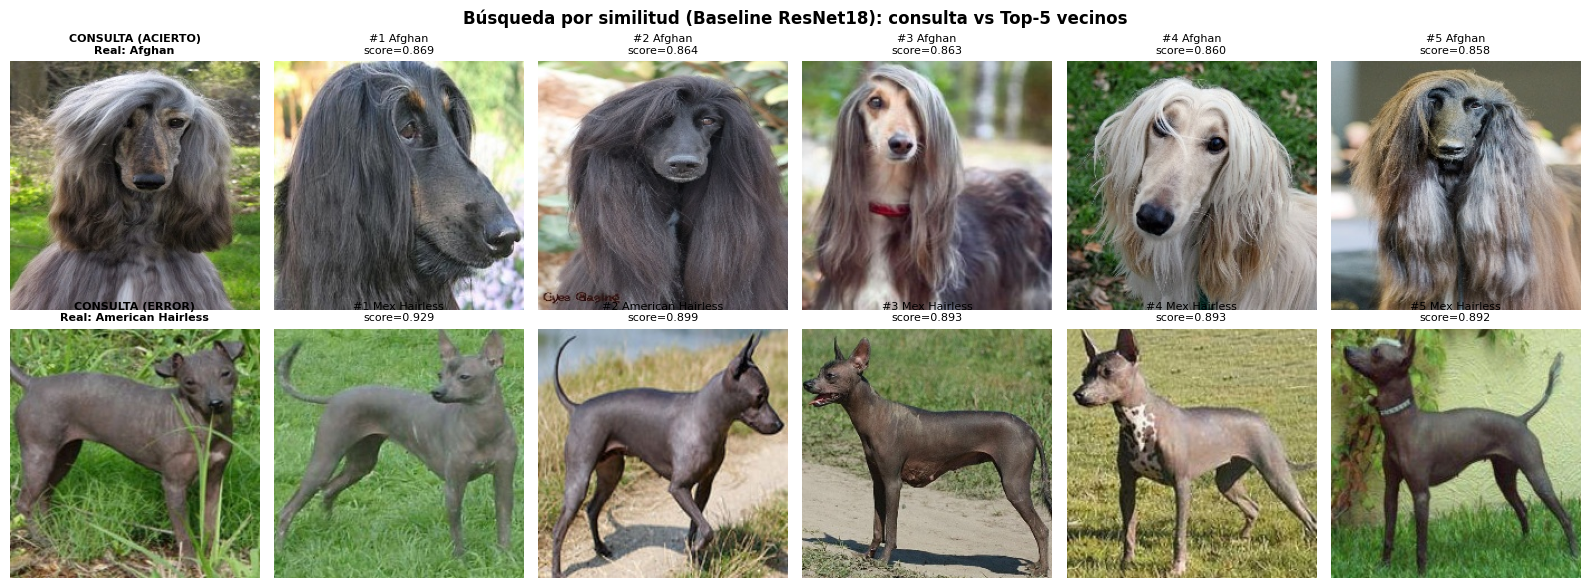

In [20]:
sim_test = emb_test_base @ emb_train_base.T
# Buscar 1 acierto y 1 fallo ilustrativo
hit_idx, miss_idx = None, None
for i in range(len(test_breeds)):
    top_idx = np.argsort(-sim_test[i])[:5]
    neighs = [Neighbor(path="", breed=str(gal_breeds[j]), score=float(sim_test[i, j])) for j in top_idx]
    pred, _ = similarity.predict_breed_from_neighbors(neighs)
    if pred == test_breeds[i] and hit_idx is None:
        hit_idx = i
    elif pred != test_breeds[i] and miss_idx is None:
        miss_idx = i
    if hit_idx is not None and miss_idx is not None:
        break

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for row, q_idx, label_tag in [(0, hit_idx, "ACIERTO"), (1, miss_idx, "ERROR")]:
    q_row = df_test.iloc[q_idx]
    axes[row, 0].imshow(bgr_to_rgb(cv2.imread(str(DATA_DIR / q_row["rel_path"]))))
    axes[row, 0].set_title(f"CONSULTA ({label_tag})\nReal: {q_row['breed']}", fontsize=8, fontweight="bold")
    axes[row, 0].axis("off")

    top5 = np.argsort(-sim_test[q_idx])[:5]
    for col, g_idx in enumerate(top5, start=1):
        g_row = df_train.iloc[g_idx]
        axes[row, col].imshow(bgr_to_rgb(cv2.imread(str(DATA_DIR / g_row["rel_path"]))))
        axes[row, col].set_title(
            f"#{col} {g_row['breed']}\nscore={sim_test[q_idx, g_idx]:.3f}", fontsize=8
        )
        axes[row, col].axis("off")

plt.suptitle("Búsqueda por similitud (Baseline ResNet18): consulta vs Top-5 vecinos", fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Modelo A (obligatorio): fine-tuning de ResNet

- **Arquitectura (`ResNet18BreedClassifier` en `src/lib/models/cnn_custom.py`):** *backbone* `ResNet18` pre-entrenado en ImageNet (`512` características tras `AdaptiveAvgPool2d`) conectado a una cabeza `Dropout(0.3) -> Linear(512, 70)`.
- **Estrategia de fine-tuning:** *fine-tuning* completo con **learning rates diferenciados** (`lr = 1e-4` en las capas convolucionales pre-entrenadas para preservar los filtros visuales generales de ImageNet sin destruirlos, y `lr = 1e-3` en la cabeza lineal recién inicializada).
- **Hiperparámetros:** optimizador `AdamW` (`weight_decay = 1e-4`), scheduler `CosineAnnealingLR`, `batch_size = 32`, hasta `15` épocas con *early stopping* (`patience = 5` monitoreando `val_acc`) y `CrossEntropyLoss(label_smoothing = 0.1)`.

In [21]:
from lib.bootstrap import build_classifier

classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
classifier.train_classifier()

INFO:lib.services.classifier_service:Loaded splits from data\splits.csv (9113 rows, 70 classes)


INFO:lib.services.classifier_service:Starting training for 'resnet18_finetuned' on cpu (train=7730, valid=687, epochs=15)
INFO:lib.services.classifier_service:[resnet18_finetuned] Epoch 01/15 | train_loss=2.3197 train_acc=0.5455 | val_loss=1.2078 val_acc=0.8879
INFO:lib.services.classifier_service:[resnet18_finetuned] Epoch 02/15 | train_loss=1.5359 train_acc=0.7715 | val_loss=1.1462 val_acc=0.9214
INFO:lib.services.classifier_service:[resnet18_finetuned] Epoch 03/15 | train_loss=1.4093 train_acc=0.8208 | val_loss=1.0978 val_acc=0.9403
INFO:lib.services.classifier_service:[resnet18_finetuned] Epoch 04/15 | train_loss=1.3381 train_acc=0.8405 | val_loss=1.1102 val_acc=0.9258
INFO:lib.services.classifier_service:[resnet18_finetuned] Epoch 05/15 | train_loss=1.2597 train_acc=0.8693 | val_loss=1.0682 val_acc=0.9360
INFO:lib.services.classifier_service:[resnet18_finetuned] Epoch 06/15 | train_loss=1.1949 train_acc=0.8941 | val_loss=1.0367 val_acc=0.9491
INFO:lib.services.classifier_service:[

In [22]:
metrics_a = classifier.evaluate_classifier()
metrics_a

INFO:lib.services.classifier_service:Loaded splits from data\splits.csv (9113 rows, 70 classes)
INFO:lib.services.classifier_service:Test metrics (resnet18_finetuned): {'accuracy': 0.9598, 'precision': 0.9625, 'recall': 0.9598, 'specificity': 0.9994, 'f1': 0.9598}


{'accuracy': 0.9598,
 'precision': 0.9625,
 'recall': 0.9598,
 'specificity': 0.9994,
 'f1': 0.9598}

### Curvas de entrenamiento y matriz de confusión (Modelo A)


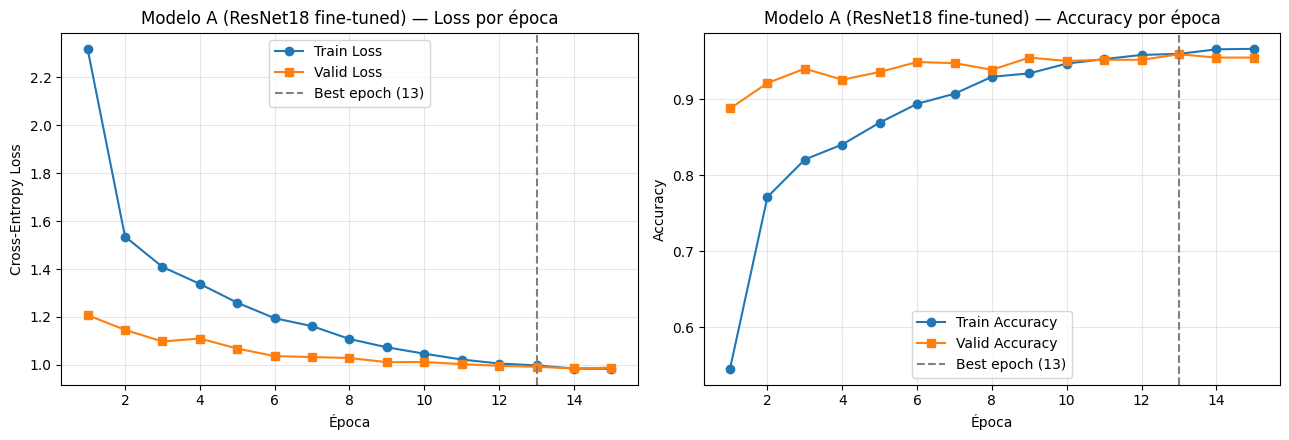

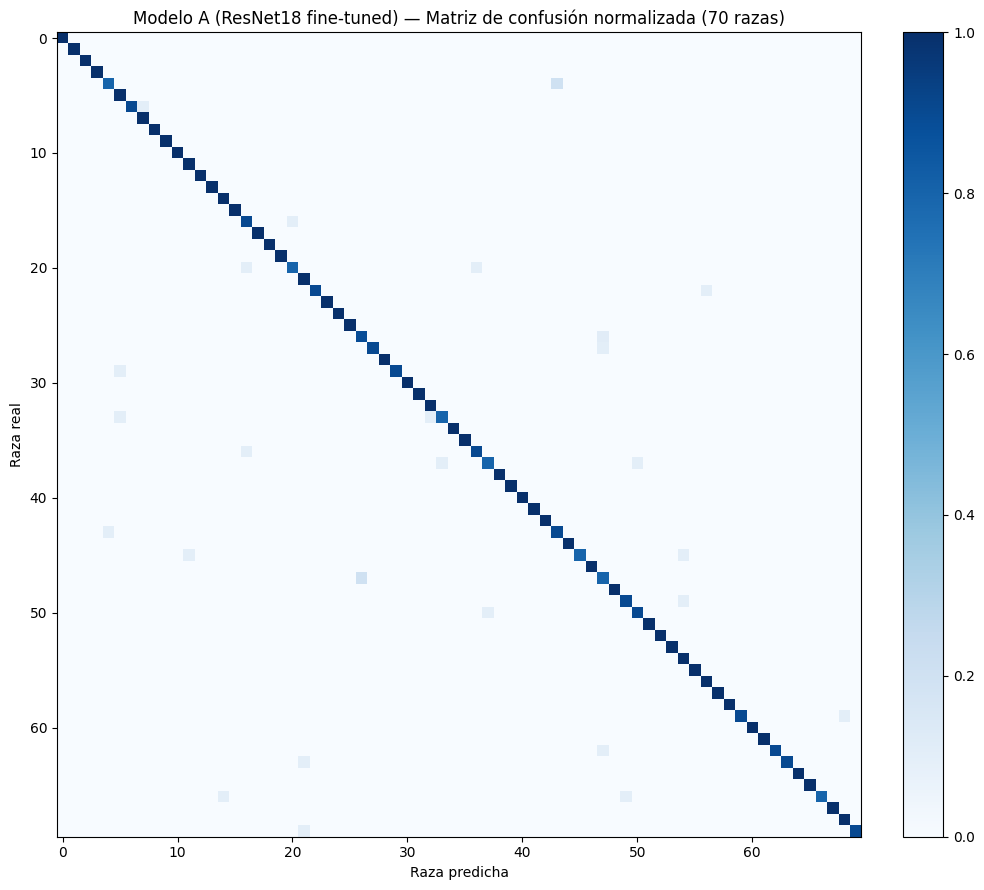

Top pares más confundidos (Modelo A (ResNet18 fine-tuned)):


,Raza real,Raza predicha,Errores,Tasa confusión
0,Labradoodle,Cockapoo,2,0.2
1,American Spaniel,Irish Spaniel,2,0.2
2,Shih-Tzu,Border Collie,1,0.1
3,Yorkie,Cairn,1,0.1
4,Schnauzer,Labradoodle,1,0.1
5,Rhodesian,Vizsla,1,0.1
6,Malinois,German Sheperd,1,0.1
7,Shih-Tzu,Lhasa,1,0.1
8,Lhasa,Pekinese,1,0.1
9,Japanese Spaniel,Pekinese,1,0.1


In [23]:
def plot_training_and_confusion(model_name: str, title_prefix: str):
    hist_data = json.loads((OUTPUT_DIR / f"history_{model_name}.json").read_text(encoding="utf-8"))
    hist = hist_data["history"]
    epochs_ran = range(1, len(hist["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(epochs_ran, hist["train_loss"], marker="o", label="Train Loss")
    axes[0].plot(epochs_ran, hist["val_loss"], marker="s", label="Valid Loss")
    axes[0].axvline(hist_data["best_epoch"], color="gray", linestyle="--", label=f"Best epoch ({hist_data['best_epoch']})")
    axes[0].set_title(f"{title_prefix} — Loss por época")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Cross-Entropy Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs_ran, hist["train_acc"], marker="o", label="Train Accuracy")
    axes[1].plot(epochs_ran, hist["val_acc"], marker="s", label="Valid Accuracy")
    axes[1].axvline(hist_data["best_epoch"], color="gray", linestyle="--", label=f"Best epoch ({hist_data['best_epoch']})")
    axes[1].set_title(f"{title_prefix} — Accuracy por época")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Matriz de confusión normalizada
    eval_npz = np.load(OUTPUT_DIR / f"eval_test_{model_name}.npz", allow_pickle=True)
    y_true = eval_npz["y_true"]
    y_pred = eval_npz["y_pred"]
    c_names = [str(c) for c in eval_npz["class_names"]]
    n_cls = len(c_names)

    cm = np.zeros((n_cls, n_cls), dtype=np.float64)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1.0
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm), where=row_sums > 0)

    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0.0, vmax=1.0)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f"{title_prefix} — Matriz de confusión normalizada (70 razas)")
    ax.set_xlabel("Raza predicha")
    ax.set_ylabel("Raza real")
    plt.tight_layout()
    plt.show()

    # Top-10 pares más confundidos fuera de la diagonal
    cm_off = cm.copy()
    np.fill_diagonal(cm_off, 0)
    flat_top = np.argsort(-cm_off.ravel())[:10]
    confused_rows = []
    for idx in flat_top:
        r, c = divmod(int(idx), n_cls)
        if cm_off[r, c] > 0:
            confused_rows.append(
                {
                    "Raza real": c_names[r],
                    "Raza predicha": c_names[c],
                    "Errores": int(cm_off[r, c]),
                    "Tasa confusión": round(float(cm_norm[r, c]), 3),
                }
            )
    print(f"Top pares más confundidos ({title_prefix}):")
    display(pd.DataFrame(confused_rows))


plot_training_and_confusion("resnet18_finetuned", "Modelo A (ResNet18 fine-tuned)")

## 7. Modelo B (obligatorio): CNN propia

- **Arquitectura (`CustomCNN` en `src/lib/models/cnn_custom.py`):** red convolucional entrenada desde cero compuesta por **5 etapas** (`ConvBlock` con doble convolución $3\times 3$, `BatchNorm2d`, activación `SiLU` y `MaxPool2d(2)`), progresando de `3 -> 32 -> 64 -> 128 -> 256 -> 512` canales sobre entrada $224\times 224$ hasta mapas $7\times 7$, seguida de `AdaptiveAvgPool2d(1,1)`, una proyección densa de **512 dimensiones** (`Linear(512, 512) -> BatchNorm1d -> SiLU`) reutilizable como embedding en la Etapa 1, `Dropout(0.4)` y capa lineal de salida `Linear(512, 70)`.
- **Hiperparámetros:** `AdamW(lr=1e-3, weight_decay=1e-4)`, `CosineAnnealingLR`, `batch_size=32`, hasta `35` épocas con *early stopping* (`patience=8`) y `CrossEntropyLoss(label_smoothing=0.1)`.
- **Resumen de decisiones de diseño:** incorporar doble convolución por etapa, `BatchNorm` y `label_smoothing` estabiliza el entrenamiento desde cero con ~115 imágenes por clase, mientras que `Global Average Pooling` reduce drásticamente los parámetros respecto de aplanar mapas $7\times 7\times 512$ ($25{,}088$ features).

In [24]:
classifier.set_active_model("cnn_custom")
classifier.train_classifier()

INFO:lib.services.classifier_service:Loaded splits from data\splits.csv (9113 rows, 70 classes)
INFO:lib.services.classifier_service:Starting training for 'cnn_custom' on cpu (train=7730, valid=687, epochs=35)
INFO:lib.services.classifier_service:[cnn_custom] Epoch 01/35 | train_loss=4.3950 train_acc=0.0284 | val_loss=4.1625 val_acc=0.0422
INFO:lib.services.classifier_service:[cnn_custom] Epoch 02/35 | train_loss=4.2066 train_acc=0.0420 | val_loss=4.1265 val_acc=0.0495
INFO:lib.services.classifier_service:[cnn_custom] Epoch 03/35 | train_loss=4.0848 train_acc=0.0558 | val_loss=3.8473 val_acc=0.0757
INFO:lib.services.classifier_service:[cnn_custom] Epoch 04/35 | train_loss=3.9232 train_acc=0.0772 | val_loss=3.6744 val_acc=0.0975
INFO:lib.services.classifier_service:[cnn_custom] Epoch 05/35 | train_loss=3.7899 train_acc=0.0956 | val_loss=3.4812 val_acc=0.1659
INFO:lib.services.classifier_service:[cnn_custom] Epoch 06/35 | train_loss=3.6530 train_acc=0.1228 | val_loss=3.4986 val_acc=0.138

In [25]:
metrics_b = classifier.evaluate_classifier()
metrics_b

INFO:lib.services.classifier_service:Loaded splits from data\splits.csv (9113 rows, 70 classes)
INFO:lib.services.classifier_service:Test metrics (cnn_custom): {'accuracy': 0.8003, 'precision': 0.8182, 'recall': 0.8001, 'specificity': 0.9971, 'f1': 0.7985}


{'accuracy': 0.8003,
 'precision': 0.8182,
 'recall': 0.8001,
 'specificity': 0.9971,
 'f1': 0.7985}

### Curvas de entrenamiento y matriz de confusión (Modelo B)

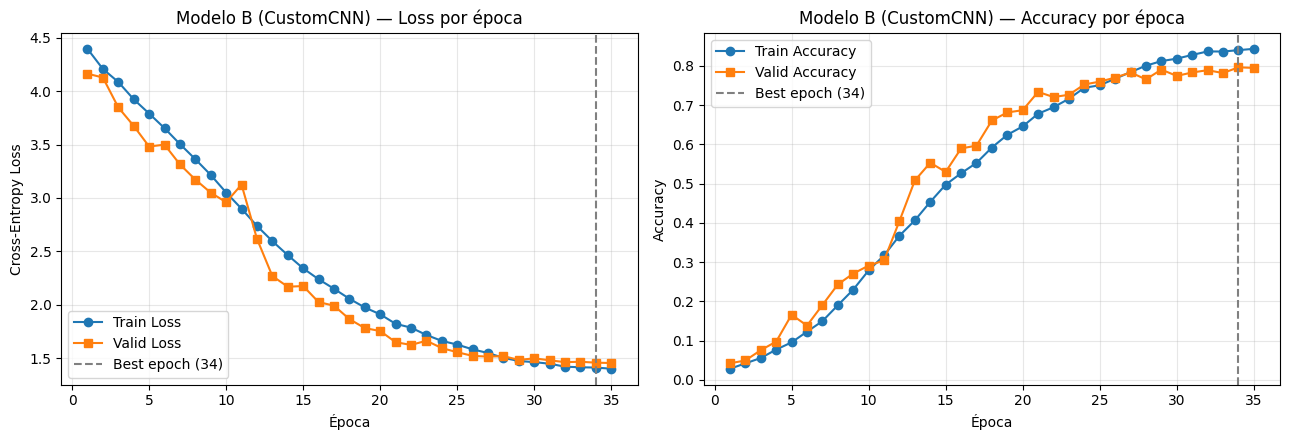

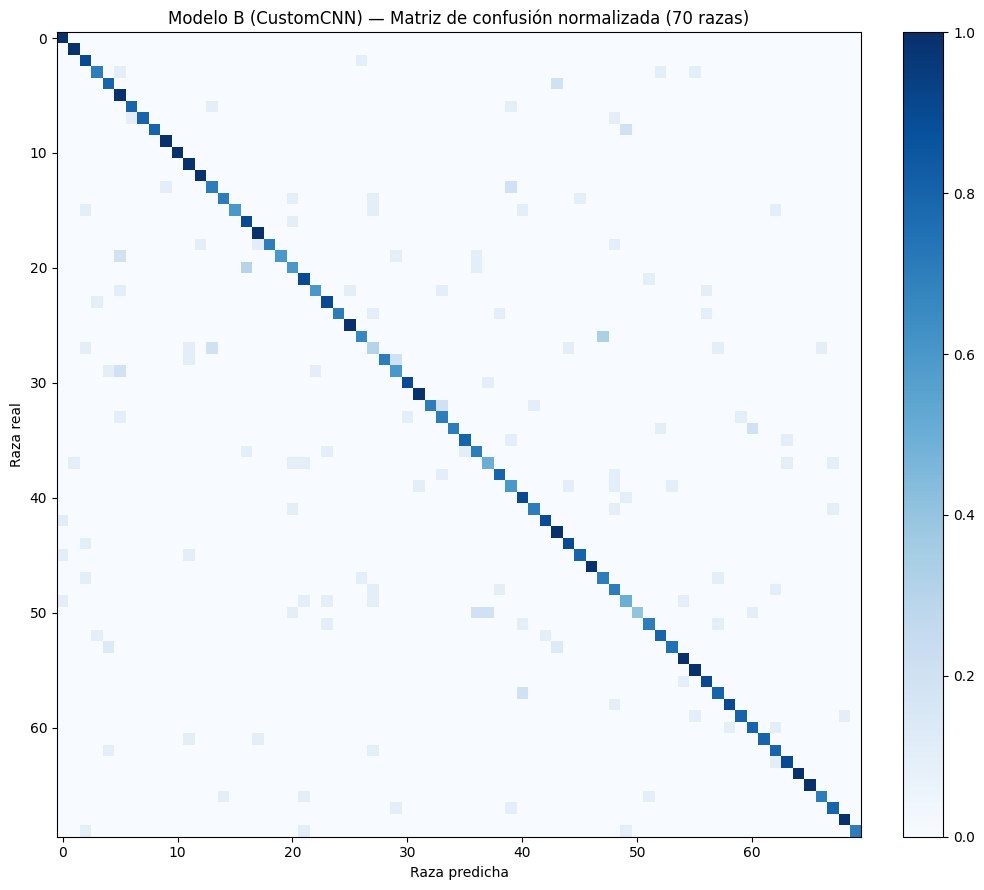

Top pares más confundidos (Modelo B (CustomCNN)):


,Raza real,Raza predicha,Errores,Tasa confusión
0,Bulldog,Boston Terrier,3,0.300
1,Cockapoo,Labradoodle,3,0.333
2,Malinois,German Sheperd,2,0.200
3,Malinois,French Bulldog,2,0.200
4,Doberman,Rottweiler,2,0.200
5,American Spaniel,Irish Spaniel,2,0.200
6,Poodle,Great Perenees,2,0.200
7,Cocker,Bluetick,2,0.200
8,Dhole,Dingo,2,0.200
9,Bull Terrier,Basenji,2,0.200


In [26]:
plot_training_and_confusion("cnn_custom", "Modelo B (CustomCNN)")

## 8. Evaluación sobre el conjunto independiente


In [27]:
def evaluate_on_independent(model_name: str) -> dict[str, float]:
    classifier.set_active_model(model_name)
    model = classifier.load_model()
    model.eval()
    transform = get_eval_transforms(settings.image_size)

    y_true, y_pred = [], []
    with torch.no_grad():
        for _, row in df_ind_single.iterrows():
            img_rgb = bgr_to_rgb(cv2.imread(str(DATA_DIR / row["rel_path"])))
            tensor = transform(image=img_rgb)["image"].unsqueeze(0)
            logits = model(tensor)
            pred_idx = int(logits.argmax(dim=1).item())
            y_true.append(int(row["label_idx"]))
            y_pred.append(pred_idx)

    y_true_arr = np.asarray(y_true)
    y_pred_arr = np.asarray(y_pred)
    acc = float(np.mean(y_true_arr == y_pred_arr))

    # Macro métricas sobre las razas presentes en el conjunto independiente
    present_classes = sorted(df_ind_single["label_idx"].unique())
    ps, rs, f1s, specs = [], [], [], []
    for c in present_classes:
        tp = int(np.sum((y_true_arr == c) & (y_pred_arr == c)))
        fp = int(np.sum((y_true_arr != c) & (y_pred_arr == c)))
        fn = int(np.sum((y_true_arr == c) & (y_pred_arr != c)))
        tn = int(np.sum((y_true_arr != c) & (y_pred_arr != c)))
        p, r, f1 = precision_recall_f1(tp, fp, fn)
        ps.append(p)
        rs.append(r)
        f1s.append(f1)
        specs.append(specificity(tn, fp))

    return {
        "accuracy": round(acc, 4),
        "precision": round(float(np.mean(ps)), 4),
        "recall": round(float(np.mean(rs)), 4),
        "specificity": round(float(np.mean(specs)), 4),
        "f1": round(float(np.mean(f1s)), 4),
    }


ind_metrics_a = evaluate_on_independent("resnet18_finetuned")
ind_metrics_b = evaluate_on_independent("cnn_custom")

df_ind_comp = pd.DataFrame(
    [
        {"Modelo": "Modelo A (ResNet18 fine-tuned)", "Split": "test", **metrics_a},
        {"Modelo": "Modelo A (ResNet18 fine-tuned)", "Split": "independent (single_dog)", **ind_metrics_a},
        {"Modelo": "Modelo B (CustomCNN)", "Split": "test", **metrics_b},
        {"Modelo": "Modelo B (CustomCNN)", "Split": "independent (single_dog)", **ind_metrics_b},
    ]
)
display(df_ind_comp)

,Modelo,Split,accuracy,precision,recall,specificity,f1
0,Modelo A (ResNet18 fine-tuned),test,0.9598,0.9625,0.9598,0.9994,0.9598
1,Modelo A (ResNet18 fine-tuned),independent (single_dog),0.6864,0.7961,0.6833,0.9955,0.7046
2,Modelo B (CustomCNN),test,0.8003,0.8182,0.8001,0.9971,0.7985
3,Modelo B (CustomCNN),independent (single_dog),0.3136,0.3545,0.3167,0.9897,0.3021


## 9. Embeddings de los modelos entrenados

- NDCG@10 de la Etapa 1 con los embeddings del baseline, del Modelo A y del Modelo B
  (`classifier.extract_custom_embedding`), con la misma galería y las mismas consultas.
- Visualización PCA o t-SNE de los embeddings de `test` de cada modelo, lado a lado y coloreada
  por raza (con un subconjunto de razas).

,Extractor,NDCG@10 (test),Precision@10 (test),Accuracy búsqueda (test),NDCG@10 (independent),Accuracy búsqueda (independent)
0,baseline (ResNet18 ImageNet),0.8739,0.8603,0.9325,0.6287,0.7288
1,Modelo A (ResNet18 fine-tuned),0.9469,0.9458,0.9641,0.7003,0.7288
2,Modelo B (CustomCNN),0.6869,0.6668,0.7543,0.2550,0.2627


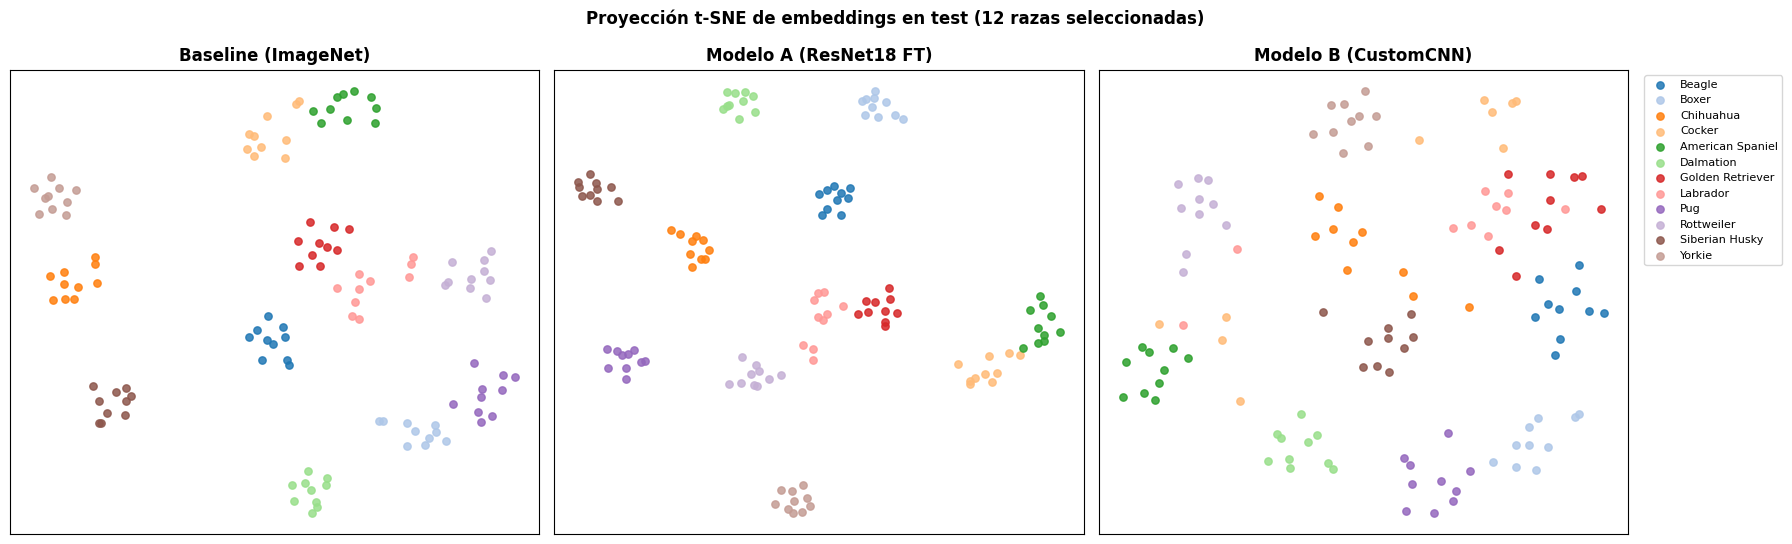

In [28]:
from sklearn.manifold import TSNE

# Extraer embeddings de galería (train), test e independent para Modelo A y Modelo B
classifier.set_active_model("resnet18_finetuned")
emb_train_a = compute_embeddings_matrix(df_train, classifier.extract_custom_embedding)
emb_test_a = compute_embeddings_matrix(df_test, classifier.extract_custom_embedding)
emb_ind_a = compute_embeddings_matrix(df_ind_single, classifier.extract_custom_embedding)

classifier.set_active_model("cnn_custom")
emb_train_b = compute_embeddings_matrix(df_train, classifier.extract_custom_embedding)
emb_test_b = compute_embeddings_matrix(df_test, classifier.extract_custom_embedding)
emb_ind_b = compute_embeddings_matrix(df_ind_single, classifier.extract_custom_embedding)

emb_comp_rows = []
for label, g_e, t_e, i_e in [
    ("baseline (ResNet18 ImageNet)", emb_train_base, emb_test_base, emb_ind_base),
    ("Modelo A (ResNet18 fine-tuned)", emb_train_a, emb_test_a, emb_ind_a),
    ("Modelo B (CustomCNN)", emb_train_b, emb_test_b, emb_ind_b),
]:
    res_test = evaluate_retrieval(g_e, gal_breeds, t_e, test_breeds, metric="cosine", top_k=10, threshold=0.55)
    res_ind = evaluate_retrieval(g_e, gal_breeds, i_e, ind_breeds, metric="cosine", top_k=10, threshold=0.55)
    emb_comp_rows.append(
        {
            "Extractor": label,
            "NDCG@10 (test)": res_test["NDCG@10"],
            "Precision@10 (test)": res_test["Precision@10"],
            "Accuracy búsqueda (test)": res_test["Accuracy_raza"],
            "NDCG@10 (independent)": res_ind["NDCG@10"],
            "Accuracy búsqueda (independent)": res_ind["Accuracy_raza"],
        }
    )

df_emb_comparison = pd.DataFrame(emb_comp_rows)
display(df_emb_comparison)

# Visualización t-SNE lado a lado sobre 12 razas de test
subset_breeds = [
    "Beagle", "Boxer", "Chihuahua", "Cocker", "American Spaniel", "Dalmation",
    "Golden Retriever", "Labrador", "Pug", "Rottweiler", "Siberian Husky", "Yorkie",
]
mask_sub = df_test["breed"].isin(subset_breeds).to_numpy()
sub_labels = df_test.loc[mask_sub, "breed"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
cmap = plt.get_cmap("tab20")

for ax, (title, embs) in zip(
    axes,
    [
        ("Baseline (ImageNet)", emb_test_base[mask_sub]),
        ("Modelo A (ResNet18 FT)", emb_test_a[mask_sub]),
        ("Modelo B (CustomCNN)", emb_test_b[mask_sub]),
    ],
):
    coords = TSNE(n_components=2, perplexity=20, random_state=SEED, init="pca").fit_transform(embs)
    for b_idx, b_name in enumerate(subset_breeds):
        pts = coords[sub_labels == b_name]
        ax.scatter(pts[:, 0], pts[:, 1], s=28, color=cmap(b_idx), label=b_name, alpha=0.85)
    ax.set_title(title, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])

axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.suptitle("Proyección t-SNE de embeddings en test (12 razas seleccionadas)", fontweight="bold")
plt.tight_layout()
plt.show()

## 10. Análisis de errores

Ejemplos de falsos positivos y falsos negativos con la imagen y su score, razas con peor
desempeño.

10 razas con menor F1 en test (Modelo A):


,Raza,Precision,Recall,F1
47,Labradoodle,0.727,0.800,0.762
4,American Spaniel,0.889,0.800,0.842
26,Cockapoo,0.800,0.889,0.842
20,Bulldog,0.889,0.800,0.842
33,Dingo,0.889,0.800,0.842
37,German Sheperd,0.889,0.800,0.842
43,Irish Spaniel,0.818,0.900,0.857
16,Boston Terrier,0.818,0.900,0.857
45,Japanese Spaniel,1.000,0.800,0.889
66,Shih-Tzu,1.000,0.800,0.889


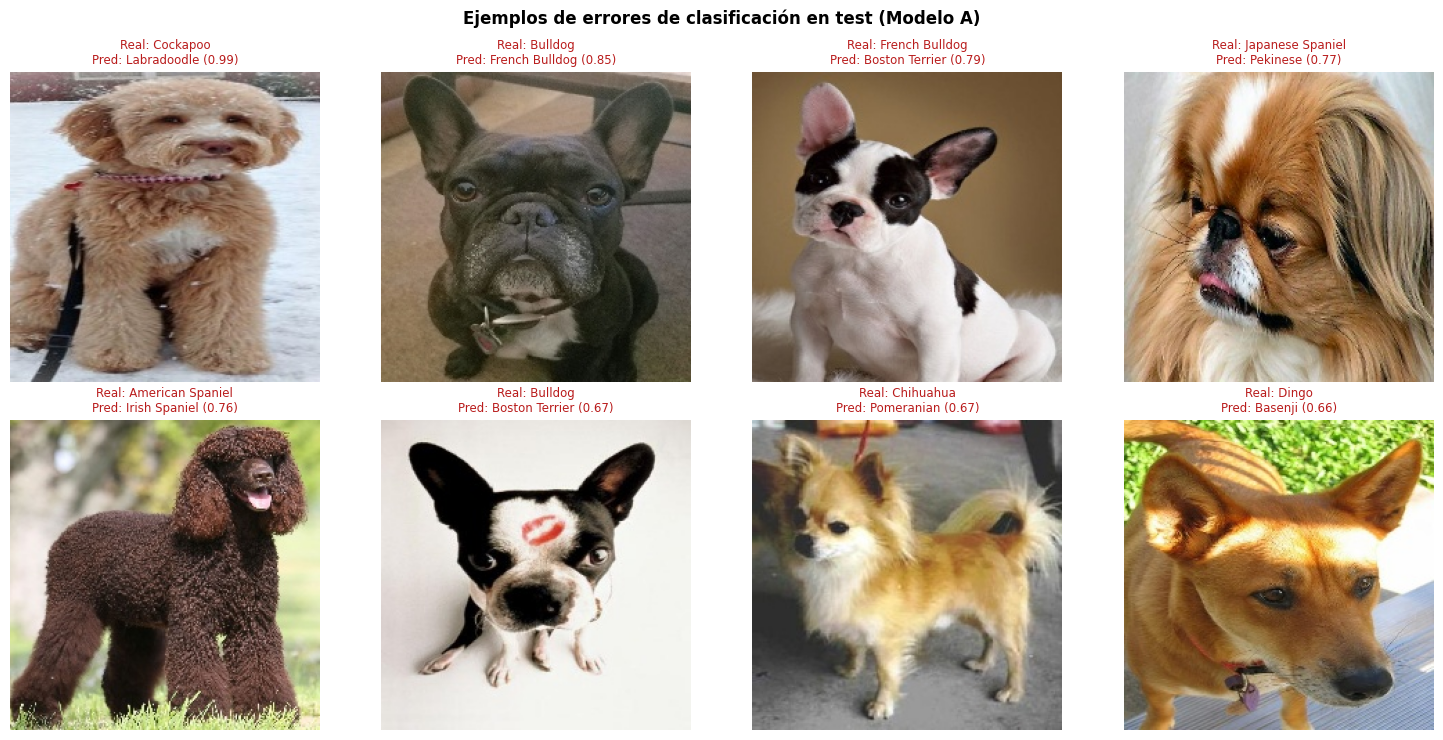

In [29]:
eval_a = np.load(OUTPUT_DIR / "eval_test_resnet18_finetuned.npz", allow_pickle=True)
y_true_a = eval_a["y_true"]
y_pred_a = eval_a["y_pred"]
probs_a = eval_a["probs"]
paths_a = eval_a["rel_paths"]

# Razas con menor F1 en Modelo A
per_breed_rows = []
for idx, b_name in enumerate(CLASS_NAMES):
    tp = int(np.sum((y_true_a == idx) & (y_pred_a == idx)))
    fp = int(np.sum((y_true_a != idx) & (y_pred_a == idx)))
    fn = int(np.sum((y_true_a == idx) & (y_pred_a != idx)))
    p, r, f1 = precision_recall_f1(tp, fp, fn)
    per_breed_rows.append({"Raza": b_name, "Precision": round(p, 3), "Recall": round(r, 3), "F1": round(f1, 3)})

df_worst_breeds = pd.DataFrame(per_breed_rows).sort_values("F1").head(10)
print("10 razas con menor F1 en test (Modelo A):")
display(df_worst_breeds)

# Ejemplos visuales de errores (Falsos Positivos / Falsos Negativos con alta confianza)
err_indices = np.where(y_true_a != y_pred_a)[0]
if len(err_indices) > 0:
    conf_err = probs_a[err_indices, y_pred_a[err_indices]]
    top_err = err_indices[np.argsort(-conf_err)[:8]]

    fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
    axes = axes.flatten()
    for ax, idx in zip(axes, top_err):
        img_rgb = bgr_to_rgb(cv2.imread(str(DATA_DIR / str(paths_a[idx]))))
        true_b = CLASS_NAMES[int(y_true_a[idx])]
        pred_b = CLASS_NAMES[int(y_pred_a[idx])]
        score_p = float(probs_a[idx, int(y_pred_a[idx])])
        ax.imshow(img_rgb)
        ax.set_title(f"Real: {true_b}\nPred: {pred_b} ({score_p:.2f})", fontsize=8.5, color="#b91c1c")
        ax.axis("off")
    for ax in axes[len(top_err):]:
        ax.axis("off")
    plt.suptitle("Ejemplos de errores de clasificación en test (Modelo A)", fontweight="bold")
    plt.tight_layout()
    plt.show()

## 11. Costo computacional

Cantidad de parámetros, tamaño en MB, tiempo de inferencia por imagen en CPU y dimensión
del embedding de cada modelo.

In [31]:
dummy_input = torch.randn(1, 3, settings.image_size, settings.image_size)


def benchmark_model_cpu(name: str, model_obj: torch.nn.Module, ckpt_path: Path | None) -> dict[str]:
    model_obj.to("cpu").eval()
    n_params = sum(p.numel() for p in model_obj.parameters())
    size_mb = round(ckpt_path.stat().st_size / (1024 * 1024), 2) if (ckpt_path and ckpt_path.exists()) else "-"

    with torch.no_grad():
        for _ in range(15):
            _ = model_obj(dummy_input)
        t0 = time.perf_counter()
        n_runs = 100
        for _ in range(n_runs):
            _ = model_obj(dummy_input)
        ms_per_img = (time.perf_counter() - t0) * 1000.0 / n_runs

    return {
        "Modelo": name,
        "Parámetros": f"{n_params:,}",
        "Tamaño checkpoint (MB)": size_mb,
        "Latencia CPU (ms/img)": round(ms_per_img, 2),
        "Dimensión embedding": settings.embedding_dim,
    }


classifier.set_active_model("resnet18_finetuned")
mod_a = classifier.load_model()
ckpt_a = classifier.active_checkpoint

classifier.set_active_model("cnn_custom")
mod_b = classifier.load_model()
ckpt_b = classifier.active_checkpoint

df_cost = pd.DataFrame(
    [
        benchmark_model_cpu("Baseline (ResNet18 ImageNet)", similarity._get_backbone(), None),
        benchmark_model_cpu("Modelo A (ResNet18 fine-tuned)", mod_a, ckpt_a),
        benchmark_model_cpu("Modelo B (CustomCNN)", mod_b, ckpt_b),
    ]
)
display(df_cost)

,Modelo,Parámetros,Tamaño checkpoint (MB),Latencia CPU (ms/img),Dimensión embedding
0,Baseline (ResNet18 ImageNet),"11,176,512",-,53.35,512
1,Modelo A (ResNet18 fine-tuned),"11,212,422",42.86,52.72,512
2,Modelo B (CustomCNN),"5,013,286",19.18,84.39,512


## 12. Comparación y elección final


In [32]:
df_final_comparison = pd.DataFrame(
    [
        {
            "Enfoque / Modelo": "Etapa 1 — Baseline (ResNet18 ImageNet)",
            "Accuracy (test)": df_baseline_eval.loc[0, "Accuracy_raza"],
            "F1 Macro (test)": "-",
            "Accuracy (independent)": df_baseline_eval.loc[2, "Accuracy_raza"],
            "NDCG@10 (test)": df_emb_comparison.loc[0, "NDCG@10 (test)"],
            "NDCG@10 (independent)": df_emb_comparison.loc[0, "NDCG@10 (independent)"],
        },
        {
            "Enfoque / Modelo": "Etapa 2 — Modelo A (ResNet18 fine-tuned)",
            "Accuracy (test)": metrics_a["accuracy"],
            "F1 Macro (test)": metrics_a["f1"],
            "Accuracy (independent)": ind_metrics_a["accuracy"],
            "NDCG@10 (test)": df_emb_comparison.loc[1, "NDCG@10 (test)"],
            "NDCG@10 (independent)": df_emb_comparison.loc[1, "NDCG@10 (independent)"],
        },
        {
            "Enfoque / Modelo": "Etapa 2 — Modelo B (CustomCNN)",
            "Accuracy (test)": metrics_b["accuracy"],
            "F1 Macro (test)": metrics_b["f1"],
            "Accuracy (independent)": ind_metrics_b["accuracy"],
            "NDCG@10 (test)": df_emb_comparison.loc[2, "NDCG@10 (test)"],
            "NDCG@10 (independent)": df_emb_comparison.loc[2, "NDCG@10 (independent)"],
        },
    ]
)
display(df_final_comparison)

,Enfoque / Modelo,Accuracy (test),F1 Macro (test),Accuracy (independent),NDCG@10 (test),NDCG@10 (independent)
0,Etapa 1 — Baseline (ResNet18 ImageNet),0.9325,-,0.7288,0.8739,0.6287
1,Etapa 2 — Modelo A (ResNet18 fine-tuned),0.9598,0.9598,0.6864,0.9469,0.7003
2,Etapa 2 — Modelo B (CustomCNN),0.8003,0.7985,0.3136,0.6869,0.2550


## 13. Descargar los checkpoints



In [34]:
print("Fuera de Colab: los checkpoints quedan en models/")

Fuera de Colab: los checkpoints quedan en models/


### Validación de detección y selección de `YOLO_CONF_THRESHOLD`

In [7]:
from lib.bootstrap import build_detection
from lib.visualization.draw import draw_detections

detection_srv = build_detection(settings, classifier)
detection_srv.classifier.set_active_model("resnet18_finetuned")

# 1. Comparación de YOLO_CONF_THRESHOLD sobre independent (single_dog, multi_dog y no_dog)
thresh_rows = []
for th in [0.15, 0.25, 0.50]:
    detection_srv.conf_threshold = th
    single_detected = 0
    multi_total_dogs = 0
    no_dog_fp_imgs = 0

    for _, row in df_ind.iterrows():
        img = cv2.imread(str(DATA_DIR / row["rel_path"]))
        dets = detection_srv.detect_dogs(img)
        if row["scenario"] == "single_dog" and len(dets) >= 1:
            single_detected += 1
        elif row["scenario"] == "multi_dog":
            multi_total_dogs += len(dets)
        elif row["scenario"] == "no_dog" and len(dets) > 0:
            no_dog_fp_imgs += 1

    n_single = int((df_ind["scenario"] == "single_dog").sum())
    n_multi = int((df_ind["scenario"] == "multi_dog").sum())
    n_nodog = int((df_ind["scenario"] == "no_dog").sum())
    thresh_rows.append(
        {
            "YOLO_CONF_THRESHOLD": th,
            "Recall imágenes single_dog": round(single_detected / max(n_single, 1), 4),
            "Promedio perros/img en multi_dog": round(multi_total_dogs / max(n_multi, 1), 2),
            "Falsos Positivos en no_dog": f"{no_dog_fp_imgs}/{n_nodog} ({100*no_dog_fp_imgs/max(n_nodog,1):.1f}%)",
        }
    )

detection_srv.conf_threshold = settings.yolo_conf_threshold
display(pd.DataFrame(thresh_rows))

INFO:lib.services.detection_service:Loading YOLO detector 'yolov8n.pt' (conf=0.15, dog_class_id=16)


,YOLO_CONF_THRESHOLD,Recall imágenes single_dog,Promedio perros/img en multi_dog,Falsos Positivos en no_dog
0,0.15,0.8305,2.27,2/30 (6.7%)
1,0.25,0.8136,2.07,2/30 (6.7%)
2,0.50,0.7203,2.07,2/30 (6.7%)


Se evaluó el detector `yolov8n.pt` (clase COCO `16 = dog`) sobre las 163 imágenes del conjunto independiente (`118` de un solo perro, `15` con múltiples perros y `30` sin perros) comparando tres umbrales de confianza (`0.15`, `0.25` y `0.50`):

- **Elección (`YOLO_CONF_THRESHOLD = 0.25`):** logra un **recall del 81.36%** en escenas individuales y un promedio de **2.07 perros detectados por imagen** en escenas grupales, manteniendo una tasa de falsos positivos del **6.7% (2/30)** en imágenes sin perros.
- **Descarte de `0.50`:** reduce el recall en imágenes individuales al **72.03%** (-9.33 p.p., omitiendo primeros planos o poses parciales) sin reducir los 2 falsos positivos de `_no_dog` (que presentan confianza > 0.50).
- **Descarte de `0.15`:** aunque recupera 2 imágenes adicionales en `single_dog` (`83.05%`), introduce detecciones duplicadas o parciales sobre un mismo animal (`2.27` cajas/imagen en `multi_dog`), entregando recortes incompletos al clasificador de razas.